In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df= pd.read_csv(r"C:\Users\himan\Education1\Projects\Quora_Challenge\dxata\questions.csv")
df.shape

(404351, 6)

In [4]:
df.sample(10)

,id,qid1,qid2,question1,question2,is_duplicate
397309,397309,776328,776329,In Dallas county what legal consecuences face ...,"In India, what are the legal damages that can ...",0
193712,193712,382381,382382,Is ISIS the ideal society Allah and the Quran ...,Is the Islamic state practicing the purest for...,0
314735,314735,617670,617671,Is Brown University a good school?,Is Brown University a good university to pursu...,0
222119,222119,437823,437824,Why can't I like comments on Instagram?,What happens if I comment on a picture on Inst...,0
159344,159344,315074,315075,Which British personalities of colonial era ha...,Who are some of the notable British people who...,0
95233,95233,189045,189046,Is there an afterlife?,Is there afterlife?,1
231208,231208,96014,455586,How does jumping off a bridge into water kill ...,If you jump from a high bridge and shoot a gre...,0
336166,336166,659084,659085,What do I do for identifying my passion?,How can I find my passion?,0
207981,207981,410285,410286,Is it possible to withdraw money from non-home...,Where do Indians waste most of their money?,0
133553,133553,264481,264482,What is the starting salary for a fresher at T...,What is the starting salary a CS fresher can e...,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 404351 entries, 0 to 404350
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   id            404351 non-null  int64
 1   qid1          404351 non-null  int64
 2   qid2          404351 non-null  int64
 3   question1     404350 non-null  str  
 4   question2     404349 non-null  str  
 5   is_duplicate  404351 non-null  int64
dtypes: int64(4), str(2)
memory usage: 18.5 MB


In [6]:
df = df.dropna(
    subset=['question1', 'question2']
).copy()

In [7]:
df.isnull().sum()

id              0
qid1            0
qid2            0
question1       0
question2       0
is_duplicate    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

is_duplicate
0    255042
1    149306
Name: count, dtype: int64
is_duplicate
0    63.074876
1    36.925124
Name: count, dtype: float64


<Axes: xlabel='is_duplicate'>

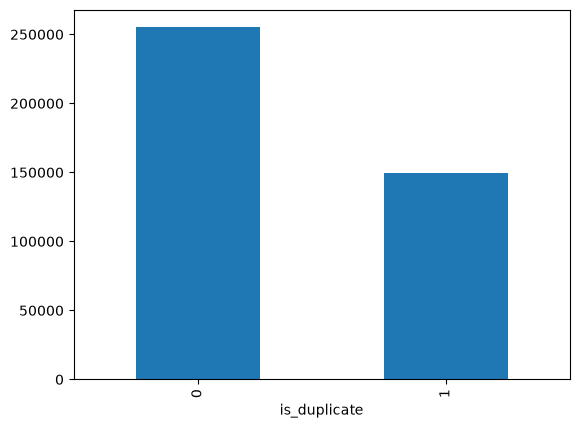

In [9]:
print(df['is_duplicate'].value_counts())
print((df['is_duplicate'].value_counts()/df['is_duplicate'].count())*100)
df['is_duplicate'].value_counts().plot(kind='bar')

In [10]:
qid = pd.Series(df['qid1'].tolist() + df['qid2'].tolist())
print('Number of unique questions',np.unique(qid).shape[0])
x = qid.value_counts()>1
print('Number of questions getting repeated',x[x].shape[0])

Number of unique questions 789795
Number of questions getting repeated 13698


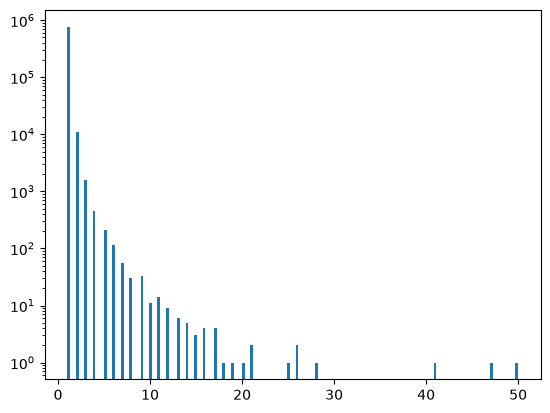

In [11]:
plt.hist(qid.value_counts().values,bins=160)
plt.yscale('log')
plt.show()

In [12]:
new_df = df

In [13]:
new_df.duplicated().sum()

np.int64(0)

In [14]:
new_df.isnull().sum()

id              0
qid1            0
qid2            0
question1       0
question2       0
is_duplicate    0
dtype: int64

In [15]:
ques_df = new_df[['question1','question2']]
ques_df.head() 

,question1,question2
0,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...
1,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...
2,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...
3,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...
4,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?


In [16]:
from sklearn.feature_extraction.text import CountVectorizer
# merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])



In [17]:
questions

['What is the step by step guide to invest in share market in india?',
 'What is the story of Kohinoor (Koh-i-Noor) Diamond?',
 'How can I increase the speed of my internet connection while using a VPN?',
 'Why am I mentally very lonely? How can I solve it?',
 'Which one dissolve in water quikly sugar, salt, methane and carbon di oxide?',
 'Astrology: I am a Capricorn Sun Cap moon and cap rising...what does that say about me?',
 'Should I buy tiago?',
 'How can I be a good geologist?',
 'When do you use シ instead of し?',
 'Motorola (company): Can I hack my Charter Motorolla DCX3400?',
 'Method to find separation of slits using fresnel biprism?',
 'How do I read and find my YouTube comments?',
 'What can make Physics easy to learn?',
 'What was your first sexual experience like?',
 'What are the laws to change your status from a student visa to a green card in the US, how do they compare to the immigration laws in Canada?',
 'What would a Trump presidency mean for current international 

In [18]:
ques_df[ques_df.isnull().any(axis=1)]


,question1,question2


In [19]:
# Drop rows with null values
ques_df = ques_df.dropna()

# Recreate questions
questions = list(ques_df['question1']) + list(ques_df['question2'])


In [20]:
ques_df.isnull().sum()


question1    0
question2    0
dtype: int64

In [21]:
import tqdm
cv = CountVectorizer(max_features=1700)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)

In [22]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(404348, 3400)

In [23]:
temp_df

,0,1,2,3,4,5,6,7,8,9,...,1690,1691,1692,1693,1694,1695,1696,1697,1698,1699
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
404346,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
404347,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
404348,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
404349,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [24]:
temp_df['is_duplicate'] = new_df['is_duplicate']

In [25]:
temp_df

,0,1,2,3,4,5,6,7,8,9,...,1691,1692,1693,1694,1695,1696,1697,1698,1699,is_duplicate
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
404346,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
404347,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
404348,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
404349,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [26]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test= train_test_split(temp_df.iloc[:,0:-1].values,temp_df.iloc[:,-1].values, test_size=0.2, random_state=1)

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
rf = RandomForestClassifier()
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.8081117843452454

In [28]:
from xgboost import XGBClassifier
xgb = XGBClassifier()
xgb.fit(X_train,y_train)
y_pred = xgb.predict(X_test)
accuracy_score(y_test,y_pred)

0.7449981451712625

is_duplicate
0    255042
1    149306
Name: count, dtype: int64
is_duplicate
0    63.074876
1    36.925124
Name: count, dtype: float64


<Axes: xlabel='is_duplicate'>

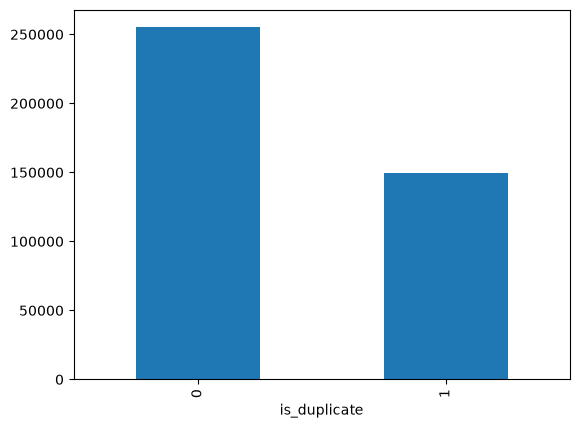

In [29]:
print(new_df["is_duplicate"].value_counts())
print((new_df["is_duplicate"].value_counts()/new_df["is_duplicate"].count())*100)
new_df['is_duplicate'].value_counts().plot(kind='bar')

In [30]:
qid = pd.Series(new_df['qid1'].tolist() + new_df['qid2'].tolist())
print('Number of unique questions',np.unique(qid).shape[0])
x = qid.value_counts()>1
print('Number of questions getting repeated',x[x].shape[0])

Number of unique questions 789795
Number of questions getting repeated 13698


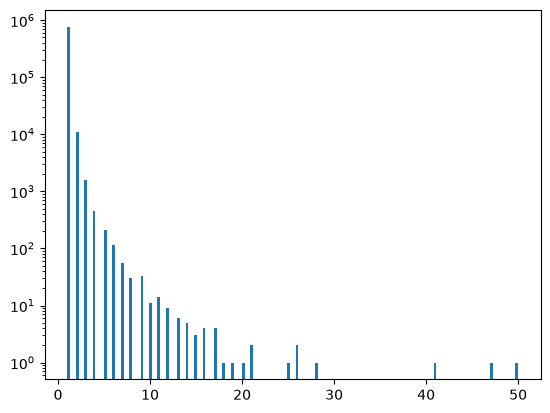

In [31]:

plt.hist(qid.value_counts().values,bins=160)
plt.yscale('log')
plt.show()

In [32]:
new_df['q1_len'] = new_df['question1'].str.len() 
new_df['q2_len'] = new_df['question2'].str.len()

In [33]:
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,66,57
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,51,88
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,73,59
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,50,65
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,76,39


In [34]:
new_df['q1_num_words'] = new_df['question1'].fillna('').str.split().str.len()
new_df['q2_num_words'] = new_df['question2'].fillna('').str.split().str.len()
new_df.head()


,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,66,57,14,12
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,51,88,8,13
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,73,59,14,10
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,50,65,11,9
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,76,39,13,7


In [35]:
def common_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return len(w1 & w2)

In [36]:
new_df['word_common'] = new_df.apply(common_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,66,57,14,12,10
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,51,88,8,13,4
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,73,59,14,10,4
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,50,65,11,9,0
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,76,39,13,7,2


In [37]:
def total_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return (len(w1) + len(w2))

In [38]:
new_df['word_total'] = new_df.apply(total_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,66,57,14,12,10,23
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,51,88,8,13,4,20
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,73,59,14,10,4,24
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,50,65,11,9,0,19
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,76,39,13,7,2,20


minimum characters 1
maximum characters 623
average num of characters 59


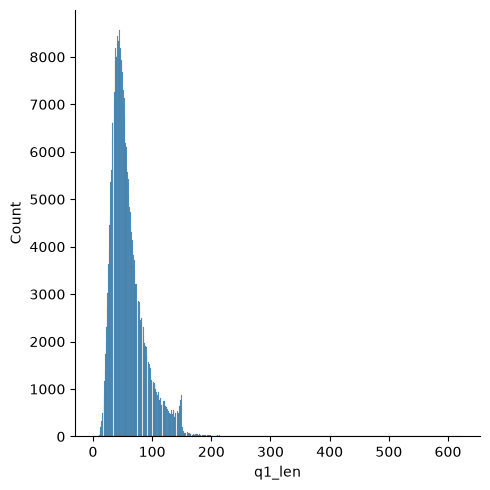

In [39]:
sns.displot(new_df['q1_len'])
print('minimum characters',new_df['q1_len'].min())
print('maximum characters',new_df['q1_len'].max())
print('average num of characters',int(new_df['q1_len'].mean()))

minimum characters 1
maximum characters 1169
average num of characters 60


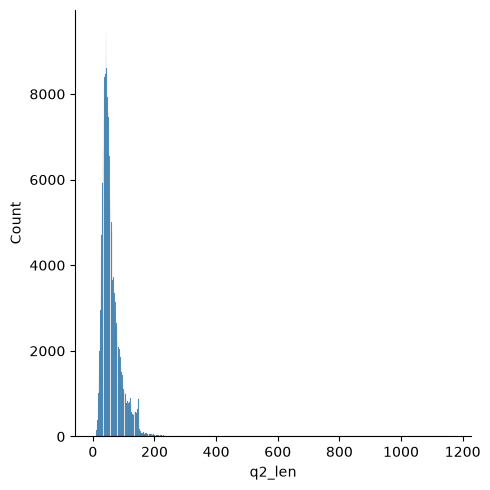

In [40]:
sns.displot(new_df['q2_len'])
print('minimum characters',new_df['q2_len'].min())
print('maximum characters',new_df['q2_len'].max())
print('average num of characters',int(new_df['q2_len'].mean()))

minimum words 1
maximum words 125
average num of words 10


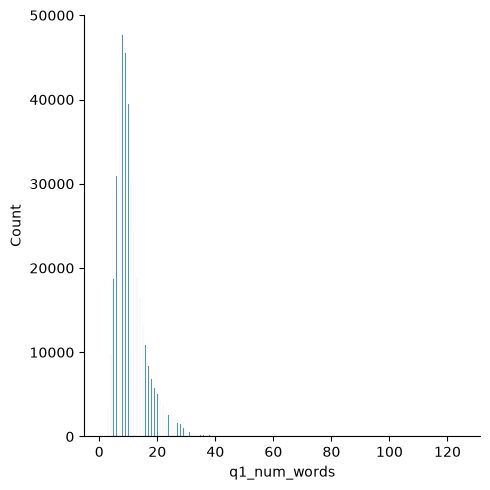

In [41]:
sns.displot(new_df['q1_num_words'])
print('minimum words',new_df['q1_num_words'].min())
print('maximum words',new_df['q1_num_words'].max())
print('average num of words',int(new_df['q1_num_words'].mean()))

minimum words 1
maximum words 237
average num of words 11


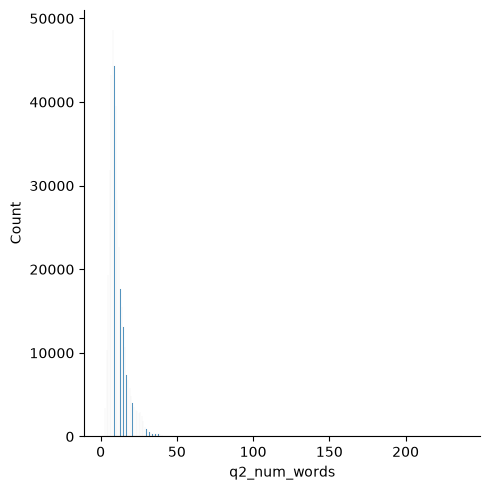

In [42]:
sns.displot(new_df['q2_num_words'])
print('minimum words',new_df['q2_num_words'].min())
print('maximum words',new_df['q2_num_words'].max())
print('average num of words',int(new_df['q2_num_words'].mean()))

C:\Users\himan\AppData\Local\Temp\ipykernel_5452\847226910.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_common'],label='non duplicate')
C:\Users\himan\AppData\Local\Temp\ipykernel_5452\847226910.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(

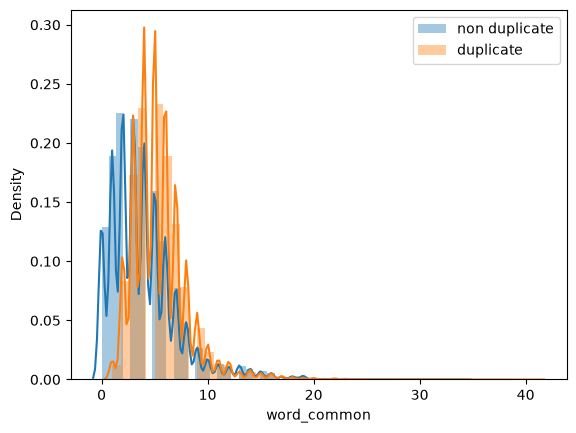

In [43]:
sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_common'],label='non duplicate')
sns.distplot(new_df[new_df['is_duplicate'] == 1]['word_common'],label='duplicate')
plt.legend()
plt.show()

C:\Users\himan\AppData\Local\Temp\ipykernel_5452\590203201.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_total'],label='non duplicate')
C:\Users\himan\AppData\Local\Temp\ipykernel_5452\590203201.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(n

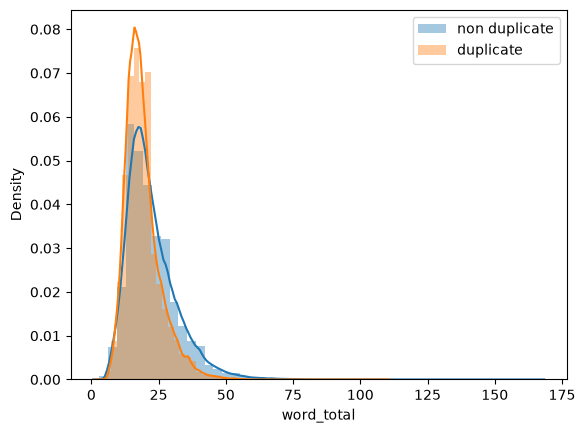

In [44]:
sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_total'],label='non duplicate')
sns.distplot(new_df[new_df['is_duplicate'] == 1]['word_total'],label='duplicate')
plt.legend()
plt.show()

In [45]:
new_df['word_share'] = round(new_df['word_common']/new_df['word_total'],2)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,66,57,14,12,10,23,0.43
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,51,88,8,13,4,20,0.20
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,73,59,14,10,4,24,0.17
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,50,65,11,9,0,19,0.00
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,76,39,13,7,2,20,0.10


C:\Users\himan\AppData\Local\Temp\ipykernel_5452\2292000331.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_share'],label='non duplicate')
C:\Users\himan\AppData\Local\Temp\ipykernel_5452\2292000331.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot

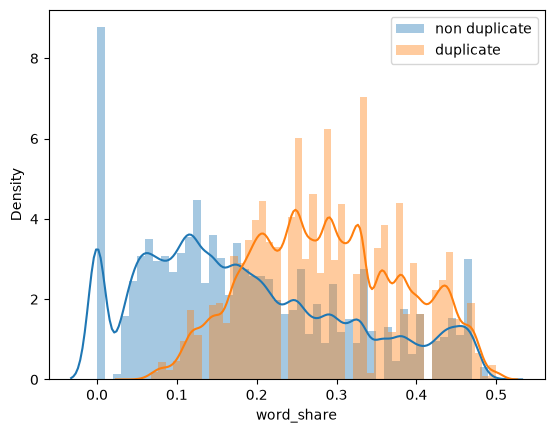

In [46]:
sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_share'],label='non duplicate')
sns.distplot(new_df[new_df['is_duplicate'] == 1]['word_share'],label='duplicate')
plt.legend()
plt.show()

In [47]:
ques_df = new_df[['question1','question2']]
ques_df.head()

,question1,question2
0,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...
1,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...
2,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...
3,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...
4,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?


In [48]:
final_df = new_df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head()

(404348, 8)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
0,0,66,57,14,12,10,23,0.43
1,0,51,88,8,13,4,20,0.20
2,0,73,59,14,10,4,24,0.17
3,0,50,65,11,9,0,19,0.00
4,0,76,39,13,7,2,20,0.10


In [49]:
from sklearn.feature_extraction.text import CountVectorizer
# merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])

cv = CountVectorizer(max_features=1500)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)

In [50]:
temp_df.shape

(404348, 3401)

In [51]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(404348, 3409)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,0,1,...,1691,1692,1693,1694,1695,1696,1697,1698,1699,is_duplicate
0,0,66,57,14,12,10,23,0.43,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,51,88,8,13,4,20,0.20,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,73,59,14,10,4,24,0.17,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,50,65,11,9,0,19,0.00,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,76,39,13,7,2,20,0.10,0,0,...,0,0,0,0,0,0,0,0,0,0


In [52]:
final_df.columns

Index(['is_duplicate',       'q1_len',       'q2_len', 'q1_num_words',
       'q2_num_words',  'word_common',   'word_total',   'word_share',
                    0,              1,
       ...
                 1691,           1692,           1693,           1694,
                 1695,           1696,           1697,           1698,
                 1699, 'is_duplicate'],
      dtype='object', length=3409)

In [53]:
final_df = final_df.drop(final_df.columns[0], axis=1)
final_df.columns

Index([      'q1_len',       'q2_len', 'q1_num_words', 'q2_num_words',
        'word_common',   'word_total',   'word_share',              0,
                    1,              2,
       ...
                 1690,           1691,           1692,           1693,
                 1694,           1695,           1696,           1697,
                 1698,           1699],
      dtype='object', length=3407)

In [54]:
final_df.shape

(404348, 3407)

In [55]:
'is_duplicate' in final_df.columns

False

In [56]:
new_df.to_csv(r"C:\Users\himan\Education1\Projects\Quora_Challenge\dxata\basic_DA_embedding(1).csv")

In [57]:
final_df.to_csv(r"C:\Users\himan\Education1\Projects\Quora_Challenge\dxata\baisc_DA_embedding.csv")

In [58]:
final_df['is_duplicate'] = new_df['is_duplicate']

In [59]:

print(final_df.shape)
final_df

(404348, 3408)


,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,0,1,2,...,1691,1692,1693,1694,1695,1696,1697,1698,1699,is_duplicate
0,66,57,14,12,10,23,0.43,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,51,88,8,13,4,20,0.20,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,73,59,14,10,4,24,0.17,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,50,65,11,9,0,19,0.00,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,76,39,13,7,2,20,0.10,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
404346,85,79,14,13,11,25,0.44,0,0,0,...,0,0,0,0,0,0,0,0,0,0
404347,41,42,8,9,5,16,0.31,0,0,0,...,0,0,0,0,0,0,0,0,0,1
404348,17,17,4,3,1,7,0.14,0,0,0,...,0,0,0,0,0,0,0,0,0,0
404349,94,127,17,25,1,40,0.02,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
final_df1= pd.read_csv(r"C:\Users\himan\Education1\Projects\Quora_Challenge\dxata\baisc_DA_embedding.csv")

In [6]:
new_df= pd.read_csv(r"C:\Users\himan\Education1\Projects\Quora_Challenge\dxata\basic_DA_embedding(1).csv")

In [7]:
final_df1['is_duplicate'] = new_df['is_duplicate']

C:\Users\himan\AppData\Local\Temp\ipykernel_19580\1596623475.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  final_df1['is_duplicate'] = new_df['is_duplicate']


In [8]:
from sklearn.model_selection import train_test_split

X = final_df1.drop(columns=['is_duplicate']).values
y = final_df1['is_duplicate'].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
rf = RandomForestClassifier()
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.8247928774576481

In [10]:
from xgboost import XGBClassifier
xgb = XGBClassifier()
xgb.fit(X_train,y_train)
y_pred = xgb.predict(X_test)
accuracy_score(y_test,y_pred)

0.7865957709904785